In [22]:
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import layers, models

In [8]:
df = pd.read_csv('mnist.csv')

In [11]:
df.columns

Index(['label', 'pixel0', 'pixel1', 'pixel2', 'pixel3', 'pixel4', 'pixel5',
       'pixel6', 'pixel7', 'pixel8',
       ...
       'pixel774', 'pixel775', 'pixel776', 'pixel777', 'pixel778', 'pixel779',
       'pixel780', 'pixel781', 'pixel782', 'pixel783'],
      dtype='object', length=785)

In [14]:
df.head(5)

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [16]:
X=df.drop(columns=['label']).values
Y=df['label'].values

In [23]:
X=X/255.0

In [ ]:
X_train,X_test,y_train,y_test =train_test_split(X,Y,test_size=0.2,random_state=42, stratify=Y)

In [32]:
model=models.Sequential([
    tf.keras.Input(shape=(784,)),

    layers.Dense(256,activation='relu', kernel_regularizer=l2(0.001)),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu',  kernel_regularizer=l2(0.001)),
    layers.Dropout(0.3),
    layers.Dense(10,activation='softmax', kernel_regularizer=l2(0.001))
])

In [33]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [36]:
early_stop=EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

In [37]:
history=  model.fit(X_train,y_train,epochs=32,validation_split=0.2,batch_size=16,callbacks=[early_stop])

Epoch 1/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.8814 - loss: 0.7048 - val_accuracy: 0.9350 - val_loss: 0.4728
Epoch 2/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9303 - loss: 0.4680 - val_accuracy: 0.9554 - val_loss: 0.3737
Epoch 3/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9377 - loss: 0.4242 - val_accuracy: 0.9607 - val_loss: 0.3529
Epoch 4/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9414 - loss: 0.4036 - val_accuracy: 0.9603 - val_loss: 0.3465
Epoch 5/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9433 - loss: 0.3949 - val_accuracy: 0.9591 - val_loss: 0.3467
Epoch 6/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9458 - loss: 0.3865 - val_accuracy: 0.9586 - val_loss: 0.3450
Epoch 7/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9445 - loss: 0.3895 - val_accuracy: 0.9606 - val_loss: 0.3388
Epoch 8/32
1680/1680 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9468 - loss: 0.3790 -

In [40]:
loss, accuracy = model.evaluate(X_test,y_test)
print('Test Accuracy', accuracy)
print('Test loss', loss)

263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9615 - loss: 0.3270
Test Accuracy 0.9615476131439209
Test loss 0.3270370066165924


In [41]:
prediction= model.predict(X_test)

263/263 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [43]:
import numpy as np

pred_labels = np.argmax(prediction, axis=1)
print(prediction.shape)    
print(pred_labels[:10])    
print(y_test[:10])        

(8400, 10)
[8 1 9 9 8 6 2 2 7 1]
[8 1 9 9 8 6 2 2 7 1]


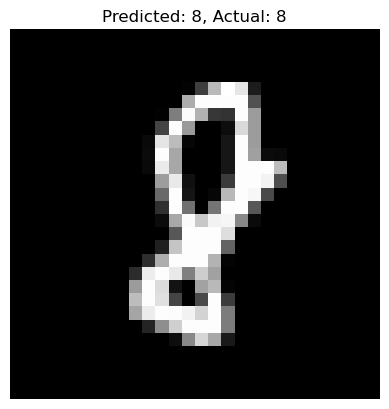

In [45]:

i = 0
plt.imshow(X_test[i].reshape(28, 28), cmap='gray')
plt.title(f"Predicted: {pred_labels[i]}, Actual: {y_test[i]}")
plt.axis('off')
plt.show()